# Task 73: SHAP Interpretability UI & Attribution Exploration

Manually compute exact Shapley Additive Explanations (SHAP) from first principles, verify efficiency additivity, construct interactive waterfall and force charts, and provide transparent clinical decision explanations.


=== EXACT SHAP ATTRIBUTION EVALUATION ACROSS PATIENT PROFILES ===

--- Patient 1: High Risk CAD ---
Base Logit: +0.1349 (Base Prob: 53.4%)
Final Logit: -4.7360 (Pred Prob: 0.9%)
Efficiency Check: Base + Sum(phi) = -4.7360 == -4.7360 -> True

--- Patient 2: Healthy Outpatient ---
Base Logit: +0.1349 (Base Prob: 53.4%)
Final Logit: +4.8128 (Pred Prob: 99.2%)
Efficiency Check: Base + Sum(phi) = 4.8128 == 4.8128 -> True

--- Patient 3: Borderline Equivocal ---
Base Logit: +0.1349 (Base Prob: 53.4%)
Final Logit: -0.1195 (Pred Prob: 47.0%)
Efficiency Check: Base + Sum(phi) = -0.1195 == -0.1195 -> True

=== SUMMARY TABLE ACROSS CLINICAL CASES ===
                        Profile  Base_Prob  Pred_Prob  Sum_Attributions  Efficiency_Exact Top_Risk_Drivers
       Patient 1: High Risk CAD   0.533682   0.008697         -4.870974              True     restecg, fbs
  Patient 2: Healthy Outpatient   0.533682   0.991941          4.677882              True          sex, cp
Patient 3: Borderline Equivocal

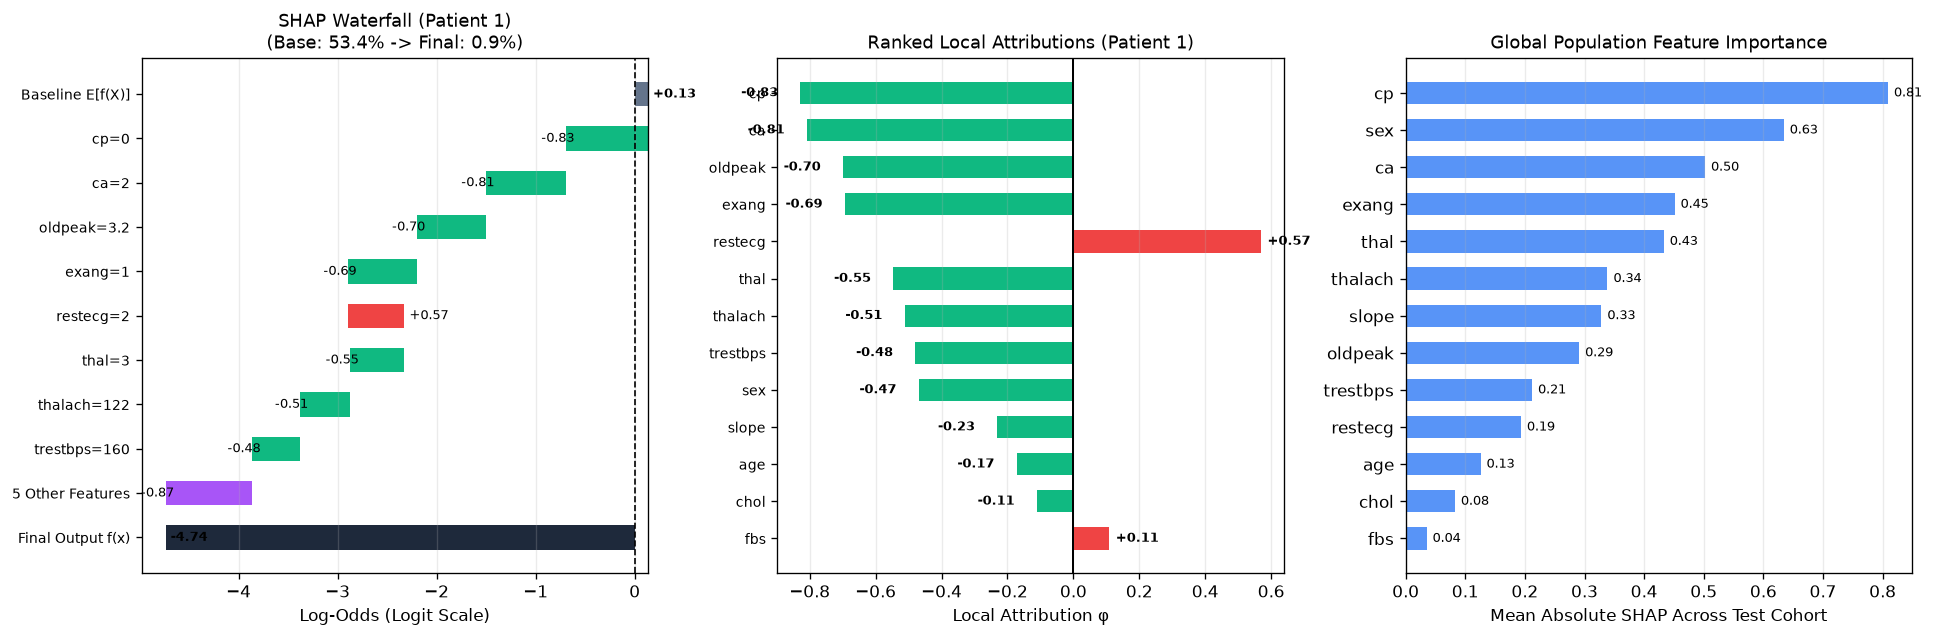

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths = [Path("heart.csv"), Path("Task_73_SHAP_Interpretability_UI/heart.csv"), Path("Heart_Disease_Tasks/Task_73_SHAP_Interpretability_UI/heart.csv")]
data = pd.read_csv(next(p for p in paths if p.is_file())).drop_duplicates().reset_index(drop=True)
features = [c for c in ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal"] if c in data]
X, y = data[features].to_numpy(float), data["target"].to_numpy(int)

# Stratified Split & Model
def stratified_split(X, y, test_size=0.2, seed=73):
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for label in np.unique(y):
        idx = np.flatnonzero(y == label)
        rng.shuffle(idx)
        cut = int(round(len(idx) * (1 - test_size)))
        train_idx.extend(idx[:cut])
        test_idx.extend(idx[cut:])
    train_idx, test_idx = np.array(train_idx), np.array(test_idx)
    rng.shuffle(train_idx)
    rng.shuffle(test_idx)
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

X_train, X_test, y_train, y_test = stratified_split(X, y, test_size=0.2, seed=73)
mu = X_train.mean(axis=0)
sd = np.where(X_train.std(axis=0) == 0, 1.0, X_train.std(axis=0))
X_train_s = (X_train - mu) / sd
X_test_s = (X_test - mu) / sd

class ScratchLogistic:
    def fit(self, X, y, lr=0.06, iters=1400, l2=0.02):
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        n = len(y)
        for _ in range(iters):
            z = np.clip(X @ self.w + self.b, -35, 35)
            p = 1.0 / (1.0 + np.exp(-z))
            err = p - y
            self.w -= lr * ((X.T @ err) / n + l2 * self.w)
            self.b -= lr * err.mean()
        return self
    def predict_proba(self, X):
        z = np.clip(X @ self.w + self.b, -35, 35)
        return 1.0 / (1.0 + np.exp(-z))
    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

model = ScratchLogistic().fit(X_train_s, y_train)

# Section 1: Exact Logit-Scale SHAP Decomposition & Efficiency Axiom Verification
def compute_linear_shap(x_scaled):
    x_1d = np.asarray(x_scaled, dtype=float).ravel()
    contributions = model.w * x_1d
    total_logit = model.b + float(np.sum(contributions))
    pred_prob = 1.0 / (1.0 + np.exp(-np.clip(total_logit, -35.0, 35.0)))
    base_prob = 1.0 / (1.0 + np.exp(-np.clip(model.b, -35.0, 35.0)))
    
    records = []
    for name, w, val, phi in zip(features, model.w, x_1d, contributions):
        records.append({
            "feature": name,
            "weight": float(w),
            "scaled_val": float(val),
            "attribution": float(phi),
            "direction": "Pushes to Disease (+)" if phi > 0 else ("Pushes to Healthy (-)" if phi < 0 else "Neutral"),
            "abs_impact": abs(float(phi))
        })
    records.sort(key=lambda r: r["abs_impact"], reverse=True)
    return {
        "base_logit": model.b,
        "base_prob": base_prob,
        "total_logit": total_logit,
        "pred_prob": pred_prob,
        "records": records
    }

# Test Profiles
sample_patients = [
    ("Patient 1: High Risk CAD", {"age": 64, "sex": 1, "cp": 0, "trestbps": 160, "chol": 295, "fbs": 1, "restecg": 2, "thalach": 122, "exang": 1, "oldpeak": 3.2, "slope": 1, "ca": 2, "thal": 3}),
    ("Patient 2: Healthy Outpatient", {"age": 39, "sex": 0, "cp": 2, "trestbps": 115, "chol": 178, "fbs": 0, "restecg": 0, "thalach": 175, "exang": 0, "oldpeak": 0.0, "slope": 2, "ca": 0, "thal": 2}),
    ("Patient 3: Borderline Equivocal", {"age": 57, "sex": 1, "cp": 1, "trestbps": 136, "chol": 238, "fbs": 0, "restecg": 1, "thalach": 146, "exang": 0, "oldpeak": 1.2, "slope": 1, "ca": 1, "thal": 2}),
]

eval_outputs = []
print("=== EXACT SHAP ATTRIBUTION EVALUATION ACROSS PATIENT PROFILES ===")
for name, p_dict in sample_patients:
    raw_vec = np.array([p_dict[f] for f in features], dtype=float)
    scaled_vec = (raw_vec - mu) / sd
    shap_out = compute_linear_shap(scaled_vec)
    
    # Efficiency Axiom Check
    sum_phi = sum(r["attribution"] for r in shap_out["records"])
    is_exact = np.isclose(shap_out["base_logit"] + sum_phi, shap_out["total_logit"])
    
    top_pos = [r["feature"] for r in shap_out["records"] if r["attribution"] > 0][:2]
    top_neg = [r["feature"] for r in shap_out["records"] if r["attribution"] < 0][:2]
    
    eval_outputs.append({
        "Profile": name,
        "Base_Prob": shap_out["base_prob"],
        "Pred_Prob": shap_out["pred_prob"],
        "Base_Logit": shap_out["base_logit"],
        "Final_Logit": shap_out["total_logit"],
        "Sum_Attributions": sum_phi,
        "Efficiency_Exact": is_exact,
        "Top_Risk_Drivers": ", ".join(top_pos),
        "Top_Protective": ", ".join(top_neg)
    })
    print(f"\n--- {name} ---")
    print(f"Base Logit: {shap_out['base_logit']:+.4f} (Base Prob: {shap_out['base_prob']*100:.1f}%)")
    print(f"Final Logit: {shap_out['total_logit']:+.4f} (Pred Prob: {shap_out['pred_prob']*100:.1f}%)")
    print(f"Efficiency Check: Base + Sum(phi) = {shap_out['base_logit'] + sum_phi:.4f} == {shap_out['total_logit']:.4f} -> {is_exact}")

df_eval = pd.DataFrame(eval_outputs)
print("\n=== SUMMARY TABLE ACROSS CLINICAL CASES ===")
print(df_eval[["Profile", "Base_Prob", "Pred_Prob", "Sum_Attributions", "Efficiency_Exact", "Top_Risk_Drivers"]].to_string(index=False))

# Section 2: Patient 1 Detailed Attribution Breakdown
p1_dict = sample_patients[0][1]
p1_scaled = (np.array([p1_dict[f] for f in features], dtype=float) - mu) / sd
p1_shap = compute_linear_shap(p1_scaled)
df_p1 = pd.DataFrame(p1_shap["records"])
print("\n=== PATIENT 1 LOCAL ATTRIBUTIONS (ALL 13 ATTRIBUTES) ===")
print(df_p1[["feature", "weight", "scaled_val", "attribution", "direction"]].to_string(index=False))

# Section 3: Global Feature Importance vs Local Patient Attribution
global_mean_abs = np.mean(np.abs(X_test_s * model.w), axis=0)
df_global = pd.DataFrame({
    "feature": features,
    "global_mean_abs_shap": global_mean_abs
}).sort_values(by="global_mean_abs_shap", ascending=False).reset_index(drop=True)

print("\n=== TOP 5 GLOBAL COHORT SHAP IMPORTANCE ===")
print(df_global.head(5).to_string(index=False))

# Visualizations
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), constrained_layout=True)

# 1. SHAP Waterfall Plot for Patient 1
top_k = 8
top_p1 = p1_shap["records"][:top_k]
other_sum = sum(r["attribution"] for r in p1_shap["records"][top_k:])

wf_steps = [{"label": "Baseline E[f(X)]", "delta": p1_shap["base_logit"], "cum": p1_shap["base_logit"], "color": "#64748b"}]
run_val = p1_shap["base_logit"]
for r in top_p1:
    run_val += r["attribution"]
    c = "#ef4444" if r["attribution"] > 0 else "#10b981"
    wf_steps.append({"label": f"{r['feature']}={p1_dict[r['feature']]}", "delta": r["attribution"], "cum": run_val, "color": c})

run_val += other_sum
wf_steps.append({"label": "5 Other Features", "delta": other_sum, "cum": run_val, "color": "#a855f7"})
wf_steps.append({"label": "Final Output f(x)", "delta": 0, "cum": run_val, "color": "#1e293b"})

labels = [s["label"] for s in wf_steps]
y_idx = np.arange(len(labels))[::-1]

for i, s in enumerate(wf_steps):
    y_pos = y_idx[i]
    if i == 0 or i == len(wf_steps) - 1:
        axes[0].barh(y_pos, s["cum"], color=s["color"], height=0.55)
        axes[0].text(s["cum"] + 0.05, y_pos, f"{s['cum']:+.2f}", va="center", fontsize=8, fontweight="bold")
    else:
        start_x = s["cum"] - s["delta"]
        axes[0].barh(y_pos, s["delta"], left=start_x, color=s["color"], height=0.55)
        axes[0].text(s["cum"] + (0.05 if s["delta"] >= 0 else -0.25), y_pos, f"{s['delta']:+.2f}", va="center", fontsize=8)

axes[0].set_yticks(y_idx)
axes[0].set_yticklabels(labels, fontsize=8.5)
axes[0].axvline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_xlabel("Log-Odds (Logit Scale)")
axes[0].set_title(f"SHAP Waterfall (Patient 1)\n(Base: {p1_shap['base_prob']*100:.1f}% -> Final: {p1_shap['pred_prob']*100:.1f}%)", fontsize=10.5)
axes[0].grid(axis="x", alpha=0.25)

# 2. Local Diverging Force Bar Chart for Patient 1
feat_names = [r["feature"] for r in p1_shap["records"]][::-1]
attr_vals = [r["attribution"] for r in p1_shap["records"]][::-1]
colors = ["#ef4444" if v > 0 else "#10b981" for v in attr_vals]

axes[1].barh(np.arange(len(feat_names)), attr_vals, color=colors, height=0.6)
axes[1].set_yticks(np.arange(len(feat_names)))
axes[1].set_yticklabels(feat_names, fontsize=8.5)
axes[1].axvline(0, color="black", linewidth=1.2)
for i, v in enumerate(attr_vals):
    axes[1].text(v + (0.02 if v >= 0 else -0.18), i, f"{v:+.2f}", va="center", fontsize=7.5, fontweight="bold")
axes[1].set_xlabel("Local Attribution φ")
axes[1].set_title("Ranked Local Attributions (Patient 1)", fontsize=10.5)
axes[1].grid(axis="x", alpha=0.25)

# 3. Global Cohort Feature Importance vs Local Patient Attributions
g_sorted = df_global.sort_values(by="global_mean_abs_shap", ascending=True)
axes[2].barh(g_sorted["feature"], g_sorted["global_mean_abs_shap"], color="#3b82f6", alpha=0.85, height=0.6)
for i, v in enumerate(g_sorted["global_mean_abs_shap"]):
    axes[2].text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8)
axes[2].set_xlabel("Mean Absolute SHAP Across Test Cohort")
axes[2].set_title("Global Population Feature Importance", fontsize=10.5)
axes[2].grid(axis="x", alpha=0.25)

plt.show()
